A critical bug in power allocation in the code.  

In [24]:
import numpy as np
import matplotlib.pyplot as plt
def plot_column_from_csv(file_path, column_name):
    data = np.genfromtxt(file_path, delimiter=',', names=True)
    column_data = data[column_name]
    window_size = 500
    moving_avg = np.convolve(column_data, np.ones(window_size)/window_size, mode='valid')
    fig, ax = plt.subplots()
    #fig(figsize=(8, 6), dpi=80)
    ax.plot(moving_avg)
    ax.set(xlabel='Episode', ylabel='Averaged Reward',  xticklabels=(['','0','2k','4k','6k','8k','10k']))
def plot_cdf_from_csv(file_path, column_name1, column_name2, ax):
    data = np.genfromtxt(file_path, delimiter=',', names=True)
    tot = data[column_name1]
    tp = data[column_name2]
    th = tp/tot
    th_cdf = np.sort(th)
    yvals = np.arange(len(th))/float(len(th)-1)
    ax.plot(th_cdf, yvals, '-')
    return ax

### Comments:
##### CDF of SINR
<img src = "image-33.png" width = 350>



##### Do NOT consider sensing in the reward
**0.** Linear function of SINR[dB]
<!--PPO_preTrained/BeamManagementEnv-v1/PPO_BeamManagementEnv-v1_0_0.pth  -->

$$r = \sum_{u=1}^{U} (SINR - 10) \lambda_u$$


/var/folders/8l/7p1hpqc101jc7313r00vlgwr0000gn/T/ipykernel_1414/362308336.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Episode', ylabel='Averaged Reward',  xticklabels=(['','0','2k','4k','6k','8k','10k']))


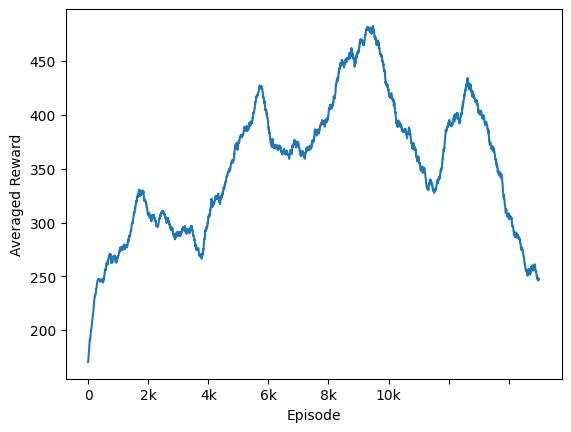

In [25]:
plot_column_from_csv('Multi-user-BM/saved_policy/PPO_logs/PPO_BeamManagementEnv-v1_log_0.csv', 'reward')

**1.** Use number of transmitted packets
$$r = \sum_{u=1}^U (R_u>4) \lambda_u $$

<!-- PPO_preTrained/BeamManagementEnv-v1/PPO_BeamManagementEnv-v1_0_1.pth -->

/var/folders/8l/7p1hpqc101jc7313r00vlgwr0000gn/T/ipykernel_1414/362308336.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Episode', ylabel='Averaged Reward',  xticklabels=(['','0','2k','4k','6k','8k','10k']))


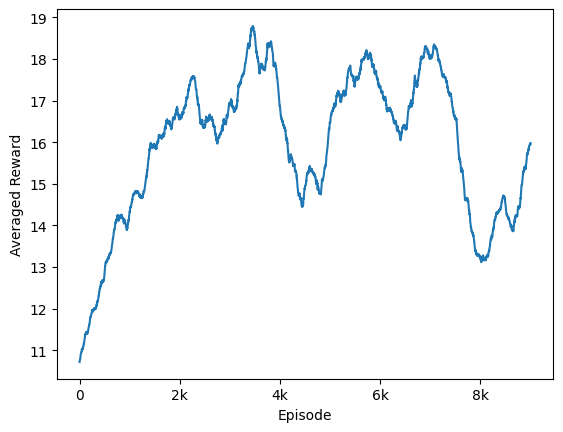

In [26]:
plot_column_from_csv('Multi-user-BM/saved_policy/PPO_logs/PPO_BeamManagementEnv-v1_log_1.csv', 'reward')

**2.** Without a penalization at high SINR 

<img src ="image-34.png" width = 350> 

<!--saved_policy/PPO_preTrained/PPO_BeamManagementEnv-v1_0_2.pth -->


/var/folders/8l/7p1hpqc101jc7313r00vlgwr0000gn/T/ipykernel_1414/362308336.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Episode', ylabel='Averaged Reward',  xticklabels=(['','0','2k','4k','6k','8k','10k']))


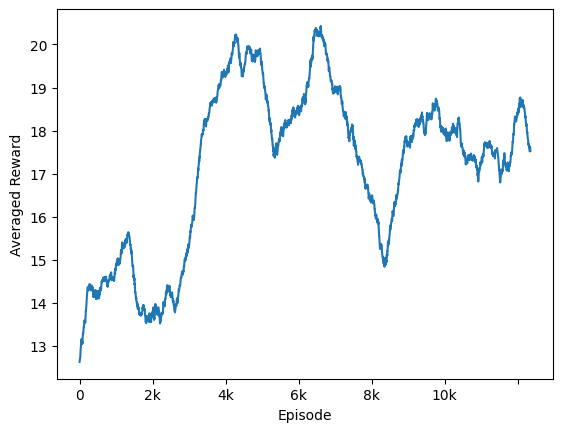

In [27]:
plot_column_from_csv('Multi-user-BM/saved_policy/PPO_logs/PPO_BeamManagementEnv-v1_log_2.csv', 'reward')

**3.** Add a penalization and use SINR
<!-- saved_policy/PPO_preTrained/PPO_BeamManagementEnv-v1_0_3.pth  -->
<img src="image-42.png" width = 350>

/var/folders/8l/7p1hpqc101jc7313r00vlgwr0000gn/T/ipykernel_1414/362308336.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Episode', ylabel='Averaged Reward',  xticklabels=(['','0','2k','4k','6k','8k','10k']))


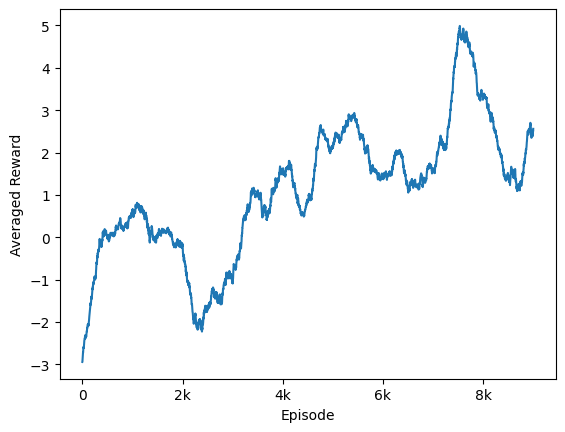

In [28]:
plot_column_from_csv('Multi-user-BM/saved_policy/PPO_logs/PPO_BeamManagementEnv-v1_log_3.csv', 'reward')

**4.** Consider both communication and sensing
<!--saved_policy/PPO_preTrained/PPO_BeamManagementEnv-v1_0_4.pth -->
$$ r = \sum_{u=1}^U (R_u>4) \lambda_u - (1-\lambda_u) \frac{|\theta_u - \hat{\theta}_u|}{\pi}  $$

In the test, although a majority of espisodes has a throughput less than 50%, there are some episodes with all packets transmitted. However, the trained policy return NaN probability. 
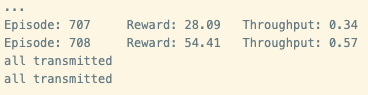
*ValueError: Expected parameter probs (Tensor of shape (25,)) of distribution Categorical(probs: torch.Size([25])) to satisfy the constraint Simplex(), but found invalid values:
tensor([nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
        nan])*

/var/folders/8l/7p1hpqc101jc7313r00vlgwr0000gn/T/ipykernel_1414/362308336.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Episode', ylabel='Averaged Reward',  xticklabels=(['','0','2k','4k','6k','8k','10k']))


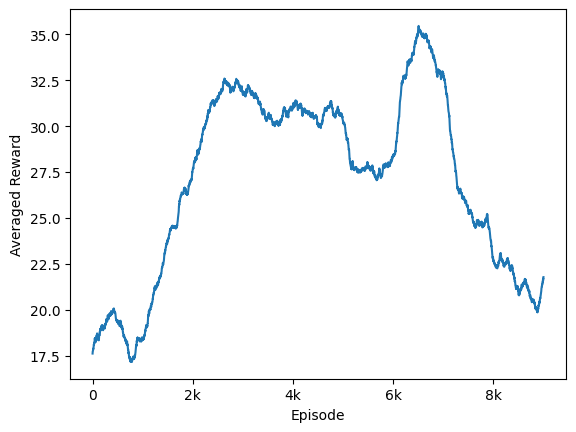

In [29]:
plot_column_from_csv('Multi-user-BM/saved_policy/PPO_logs/PPO_BeamManagementEnv-v1_log_4.csv', 'reward')

**5.** Add more information to the state
$$\mathcal{S} = \{ [\boldsymbol{b}_1,\cdots, \boldsymbol{b}_U], [B_1,\cdots, B_U], [\lambda_1, \cdots, \lambda_U]\}$$

where $\boldsymbol{b}_u$ is the beamforming output, $B_u$ is the remained packets in the buffer, and $\lambda_u$ is the user's type.

/var/folders/8l/7p1hpqc101jc7313r00vlgwr0000gn/T/ipykernel_1414/362308336.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Episode', ylabel='Averaged Reward',  xticklabels=(['','0','2k','4k','6k','8k','10k']))


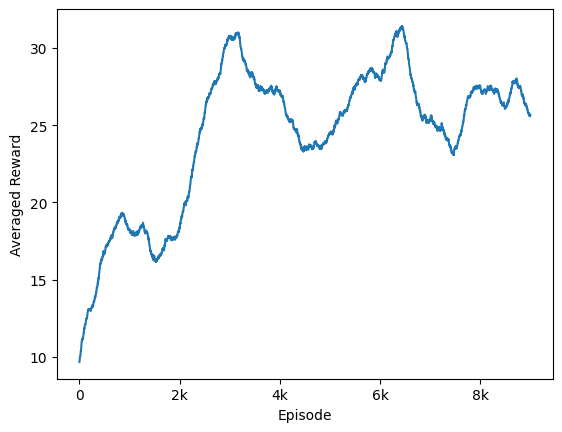

In [30]:
plot_column_from_csv('Multi-user-BM/saved_policy/PPO_logs/PPO_BeamManagementEnv-v1_log_5.csv', 'reward')

Text(0.5, 0, 'Packet throughput')

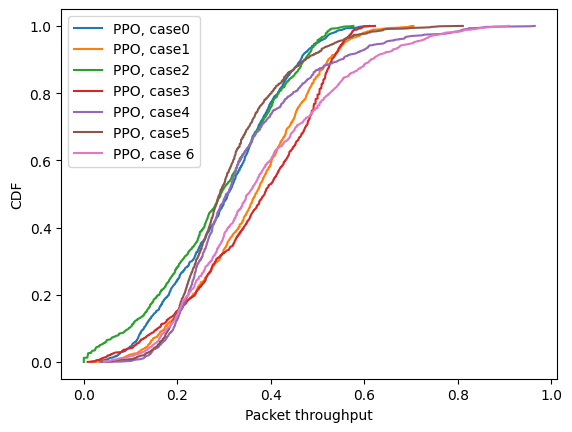

In [31]:
fig, ax = plt.subplots()
for N in [0,1,2,3,4,5,6]:
    ax = plot_cdf_from_csv('Multi-user-BM/saved_policy/PPO_logs/TEST_PPO_BeamManagementEnv-v1_log_'+str(N)+'.csv', 'total_packet_num', 'transmitted_packets',ax)
ax.legend(['PPO, case0', 'PPO, case1','PPO, case2', 'PPO, case3','PPO, case4', 'PPO, case5','PPO, case 6'])

ax.set_ylabel('CDF')
ax.set_xlabel('Packet throughput')

Conclusion:
- Throughput results of PPO are close to that of 1-TDMA.
- Througput of most episodes is below 50%.
- The trained policies do not encourage packets transmission.

**6.** The reward increases as more packets are transmitted.
$$\mathcal{S} = \{ [\boldsymbol{b}_1, \cdots, \boldsymbol{b}_U], [B_{1},\cdots, B_U], [\text{total-packets}],[\lambda_1, \cdots, \lambda_U]\}$$

$$ 
    r = \sum_{u=1}^U(1 + \frac{\text{transmitted-packets}}{\text{total-packets}} )(R_u>4) \lambda_u + 0.5*(1-\lambda_u) (beamwidth - |\theta_u - \hat{\theta}_u|)
$$

##### Check the X-TDMA 
$X$-TDMA denotes that the BS assign a sensing slot of every user before every $X$ communication slots. 

Text(0.5, 0, 'Packet throughput')

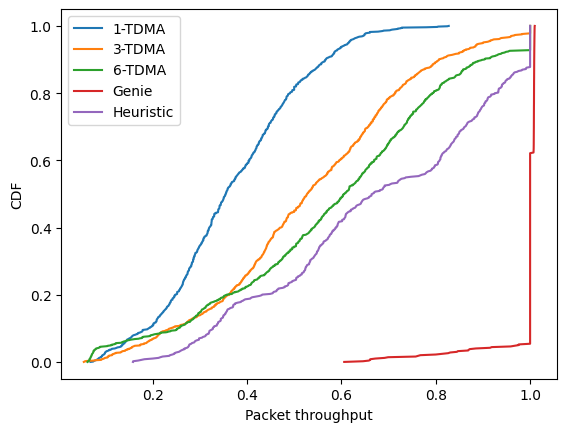

In [32]:
fig, ax = plt.subplots()
for N in [1,3,6]:
    th = np.loadtxt('Multi-user-BM/results_bm/Thp_' + str(N) + 'TDMA')
    th_cdf = np.sort(th)
    yvals = np.arange(len(th))/float(len(th)-1)
    ax.plot(th_cdf, yvals, '-')
th = np.loadtxt('Multi-user-BM/results_bm/Thp_genie')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')
th = np.loadtxt('Multi-user-BM/results_bm/Thp_heuristic')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')
ax.legend(['1-TDMA','3-TDMA','6-TDMA', 'Genie', 'Heuristic'])

ax.set_ylabel('CDF')
ax.set_xlabel('Packet throughput')

